# TRUSTSR Lab 06 — Recovery Interruption, Retry, and Idempotence

**Status:** Synthetic fault-injection simulation | Version 1.0.0

## Why this follows Lab 05
Lab 05 measured how missing dependency edges can cause the recovery planner to miss semantically affected nodes. It also exposed an important metric distinction: a node can be semantically affected while its literal stored value still equals the trusted snapshot. This lab reports **planner false negatives** separately from **literal value mismatches**.

## Objective
Inject an interruption into a selective-recovery operation, retry it, and compare a restart-from-beginning approach with a journaled in-memory approach. Measure attempts, writes, completion, residual value mismatches, and idempotence.

**Evidence boundary:** this is an in-memory synthetic model. Its journal is not durable across an actual process or machine crash. It does not establish production crash consistency, database atomicity, or security.

## 1. Configuration

In [1]:
from datetime import datetime, timezone
import random, sys, platform
import pandas as pd
import matplotlib.pyplot as plt

SEED = 20261016
N_TRIALS = 250
N_NODES = 30
EDGE_PROBABILITY = 0.08
CRASH_AFTER_WRITES = [0, 1, 3, 5, 10]

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence classification: synthetic fault-injection simulation")
print({"seed": SEED, "trials": N_TRIALS, "nodes": N_NODES,
       "crash_after_writes": CRASH_AFTER_WRITES})

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
Execution UTC: 2026-10-11T10:27:06.069830+00:00
Evidence classification: synthetic fault-injection simulation
{'seed': 20261016, 'trials': 250, 'nodes': 30, 'crash_after_writes': [0, 1, 3, 5, 10]}


## 2. Graph, snapshot, and recovery helpers

In [2]:
def make_dag(rng, n, p):
    nodes = [f"R{i:02d}" for i in range(n)]
    edges = [(nodes[i], nodes[j]) for i in range(n) for j in range(i + 1, n)
             if rng.random() < p]
    return nodes, edges

def closure(nodes, edges, sources):
    adj = {n: [] for n in nodes}
    for u, v in edges:
        adj[u].append(v)
    seen, stack = set(sources), list(sources)
    while stack:
        u = stack.pop()
        for v in adj[u]:
            if v not in seen:
                seen.add(v)
                stack.append(v)
    return seen

def snapshot(nodes, rng):
    return {n: f"trusted::{n}::{rng.randrange(10000, 99999)}" for n in nodes}

def inject_compromise(trusted, source):
    current = dict(trusted)
    current[source] = f"COMPROMISED::{source}"
    return current

def count_mismatches(current, trusted, nodes):
    return sum(current[n] != trusted[n] for n in nodes)

print("Helpers defined.")

Helpers defined.


## 3. Recovery implementations and a unit test

In [3]:
def recovery_attempt(current, trusted, plan, journal, crash_after, use_journal):
    state = dict(current)
    writes = 0
    for node in sorted(plan):
        if use_journal and journal.get(node) == "done" and state[node] == trusted[node]:
            continue
        state[node] = trusted[node]
        writes += 1
        if use_journal:
            journal[node] = "done"
        if crash_after is not None and crash_after > 0 and writes == crash_after:
            return state, False, writes
    return state, True, writes

def recover_with_retry(current, trusted, plan, crash_after, use_journal):
    state = dict(current)
    journal = {}
    attempts = 0
    total_writes = 0
    while attempts < 5:
        attempts += 1
        injected_crash = crash_after if attempts == 1 else None
        state, complete, writes = recovery_attempt(
            state, trusted, plan, journal, injected_crash, use_journal
        )
        total_writes += writes
        if complete:
            return state, complete, attempts, total_writes, journal
    return state, False, attempts, total_writes, journal

tiny_trusted = {"A": "trusted-A", "B": "trusted-B", "C": "trusted-C"}
tiny_current = {"A": "bad-A", "B": "bad-B", "C": "trusted-C"}
tiny_plan = {"A", "B"}
s, done, attempts, writes, journal = recover_with_retry(
    tiny_current, tiny_trusted, tiny_plan, 1, True
)
assert done and all(s[n] == tiny_trusted[n] for n in tiny_plan)
s2, done2, _, writes2, _ = recover_with_retry(s, tiny_trusted, tiny_plan, None, True)
assert done2 and s2 == s
print("Unit tests passed.")

Unit tests passed.


## 4. Run paired fault-injection trials

In [4]:
rows = []
for trial in range(N_TRIALS):
    rng = random.Random(SEED + trial)
    nodes, edges = make_dag(rng, N_NODES, EDGE_PROBABILITY)
    source = rng.choice(nodes[:max(2, N_NODES // 3)])
    trusted = snapshot(nodes, rng)
    current = inject_compromise(trusted, source)
    truth = closure(nodes, edges, {source})
    plan = set(truth)  # Complete graph supplied to planner in this experiment.

    for crash_after in CRASH_AFTER_WRITES:
        for method, use_journal in [("restart_from_beginning", False), ("journaled_in_memory", True)]:
            recovered, complete, attempts, total_writes, journal = recover_with_retry(
                current, trusted, plan, crash_after, use_journal
            )
            rows.append({
                "trial": trial, "method": method, "crash_after_writes": crash_after,
                "node_count": len(nodes), "affected_closure_size": len(truth),
                "plan_size": len(plan), "attempts": attempts, "total_writes": total_writes,
                "recovery_complete": complete,
                "all_node_value_mismatches": count_mismatches(recovered, trusted, nodes),
                "residual_affected_value_mismatches": sum(
                    recovered[n] != trusted[n] for n in truth
                ),
                "planner_false_negative_count": len(truth - plan),
                "final_plan_matches_trusted": all(recovered[n] == trusted[n] for n in plan)
            })

results_df = pd.DataFrame(rows)
assert len(results_df) == N_TRIALS * len(CRASH_AFTER_WRITES) * 2
assert results_df["recovery_complete"].all()
assert results_df["planner_false_negative_count"].eq(0).all()
assert results_df["residual_affected_value_mismatches"].eq(0).all()
assert results_df["final_plan_matches_trusted"].all()
print("Trial rows:", len(results_df))
print("Completion and final-state assertions passed.")
display(results_df.head())

Trial rows: 2500
Completion and final-state assertions passed.


   trial                  method  crash_after_writes  node_count  affected_closure_size  plan_size  attempts  total_writes  recovery_complete  all_node_value_mismatches  \
0      0  restart_from_beginning                   0          30                      6          6         1             6               True                          0   
1      0     journaled_in_memory                   0          30                      6          6         1             6               True                          0   
2      0  restart_from_beginning                   1          30                      6          6         2             7               True                          0   
3      0     journaled_in_memory                   1          30                      6          6         2             6               True                          0   
4      0  restart_from_beginning                   3          30                      6          6         2             9               Tru

## 5. Aggregate results and plot measured synthetic metrics

   crash_after_writes                  method  mean_attempts  mean_total_writes  completion_rate  mean_residual_affected_mismatches  mean_all_node_mismatches
0                   0     journaled_in_memory          1.000              5.468              1.0                                0.0                       0.0
1                   0  restart_from_beginning          1.000              5.468              1.0                                0.0                       0.0
2                   1     journaled_in_memory          2.000              5.468              1.0                                0.0                       0.0
3                   1  restart_from_beginning          2.000              6.468              1.0                                0.0                       0.0
4                   3     journaled_in_memory          1.744              5.468              1.0                                0.0                       0.0
5                   3  restart_from_beginning       

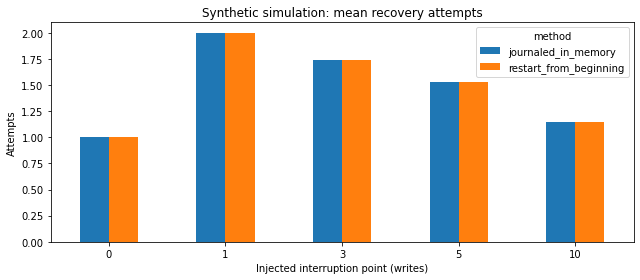

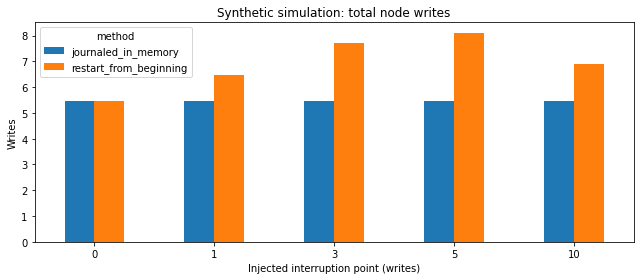

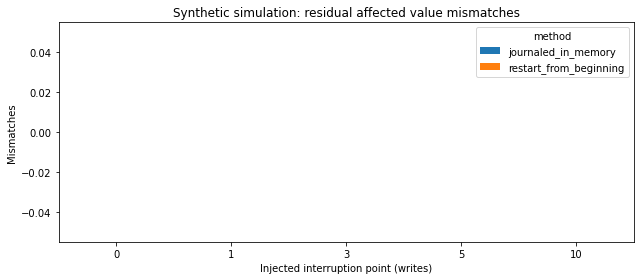

In [5]:
summary_df = results_df.groupby(["crash_after_writes", "method"]).agg(
    mean_attempts=("attempts", "mean"),
    mean_total_writes=("total_writes", "mean"),
    completion_rate=("recovery_complete", "mean"),
    mean_residual_affected_mismatches=("residual_affected_value_mismatches", "mean"),
    mean_all_node_mismatches=("all_node_value_mismatches", "mean")
).reset_index()
display(summary_df)

for metric, title, ylabel in [
    ("mean_attempts", "Synthetic simulation: mean recovery attempts", "Attempts"),
    ("mean_total_writes", "Synthetic simulation: total node writes", "Writes"),
    ("mean_residual_affected_mismatches", "Synthetic simulation: residual affected value mismatches", "Mismatches")
]:
    pivot = summary_df.pivot(index="crash_after_writes", columns="method", values=metric)
    ax = pivot.plot(kind="bar", figsize=(9, 4))
    ax.set_title(title)
    ax.set_xlabel("Injected interruption point (writes)")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()

## 6. Idempotence and metric semantics

In [6]:
idempotence_rows = []
for trial in range(min(50, N_TRIALS)):
    rng = random.Random(SEED + 900000 + trial)
    nodes, edges = make_dag(rng, N_NODES, EDGE_PROBABILITY)
    trusted = snapshot(nodes, rng)
    source = rng.choice(nodes[:max(2, N_NODES // 3)])
    current = inject_compromise(trusted, source)
    plan = closure(nodes, edges, {source})
    journal = {}
    first_state, first_done, first_writes = recovery_attempt(
        current, trusted, plan, journal, None, True
    )
    second_state, second_done, second_writes = recovery_attempt(
        first_state, trusted, plan, journal, None, True
    )
    idempotence_rows.append({
        "trial": trial, "first_complete": first_done, "second_complete": second_done,
        "first_writes": first_writes, "second_writes": second_writes,
        "state_unchanged_on_retry": first_state == second_state
    })

idempotence_df = pd.DataFrame(idempotence_rows)
assert idempotence_df["first_complete"].all()
assert idempotence_df["second_complete"].all()
assert idempotence_df["state_unchanged_on_retry"].all()
assert idempotence_df["second_writes"].eq(0).all()
display(idempotence_df.head())
print("Idempotence assertions passed for", len(idempotence_df), "synthetic trials.")

print("Metric definitions:")
print("- planner_false_negative_count: truly affected nodes missing from the recovery plan.")
print("- residual_affected_value_mismatches: affected nodes whose literal values differ from trusted values.")
print("- all_node_value_mismatches: all nodes whose literal values differ from trusted values.")
print("A semantically affected node can still have an unchanged literal value in this synthetic model.")

   trial  first_complete  second_complete  first_writes  second_writes  state_unchanged_on_retry
0      0            True             True             2              0                      True
1      1            True             True             4              0                      True
2      2            True             True             5              0                      True
3      3            True             True            19              0                      True
4      4            True             True             7              0                      True

Idempotence assertions passed for 50 synthetic trials.
Metric definitions:
- planner_false_negative_count: truly affected nodes missing from the recovery plan.
- residual_affected_value_mismatches: affected nodes whose literal values differ from trusted values.
- all_node_value_mismatches: all nodes whose literal values differ from trusted values.
A semantically affected node can still have an unchanged literal value in this synthetic model.


## 7. Export CSVs

In [7]:
results_df.to_csv("trustsr_lab06_fault_injection_trials.csv", index=False)
summary_df.to_csv("trustsr_lab06_retry_cost_summary.csv", index=False)
idempotence_df.to_csv("trustsr_lab06_idempotence_checks.csv", index=False)

for name in [
    "trustsr_lab06_fault_injection_trials.csv",
    "trustsr_lab06_retry_cost_summary.csv",
    "trustsr_lab06_idempotence_checks.csv"
]:
    print("Created:", name)
print("Evidence classification: synthetic fault-injection simulation only.")

Created: trustsr_lab06_fault_injection_trials.csv
Created: trustsr_lab06_retry_cost_summary.csv
Created: trustsr_lab06_idempotence_checks.csv
Evidence classification: synthetic fault-injection simulation only.


## 8. Interpretation limits

### This lab can support
- Reproducible synthetic measurements of interruption, retry count, write count, and final value consistency.
- An in-memory idempotence check for reapplying a completed journaled plan.
- Clear separation between planner false negatives and literal state-value mismatches.

### This lab cannot support
- Durable recovery after a real process, kernel, or machine crash.
- Database/filesystem atomicity, durable journal guarantees, concurrent-write safety, distributed coordination, cryptographic authenticity, or rollback of external side effects.
- A general claim that journaled recovery is superior; any conclusion must be restricted to measured behavior in this implementation.

### Publication wording
“We evaluated interruption and retry behavior in an in-memory synthetic recovery model. Results include completion, retry attempts, write count, final value mismatches, and idempotence checks. These results do not establish durable crash consistency or production effectiveness.”

### Next engineering milestone
Persist snapshots and the recovery journal in a local database, add transaction IDs and version checks, terminate/restart the process between durable writes, and test restart recovery. Do not describe that as production-ready without durability and failure testing.